NOTA: Ejecutar con GPU

In [ ]:
!pip install tabpfn
!pip install tabpfn_extensions
!pip install mapie
!pip install MLstatkit

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from tabpfn import TabPFNClassifier, TabPFNRegressor
from tabpfn.constants import ModelVersion
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, recall_score, confusion_matrix, brier_score_loss, mean_absolute_error, mean_squared_error, r2_score
import shap
from tabpfn_extensions import interpretability
from sklearn.utils import resample
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mapie.classification import SplitConformalClassifier
from mapie.regression import SplitConformalRegressor
from mapie.utils import train_conformalize_test_split

# Import dataset

Dado que TabPFN puede trabajar con valores nulos, trabajamos con el dataset not-imputed.

In [3]:
df = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/dataset-modificado.csv')

In [4]:
df.dtypes.value_counts()

,count
float64,72
int64,28


# Selección de modelo

https://drive.google.com/file/d/1L7BdHiq3SBcNTtx3S3sHYuny_TxF5UrQ/view?usp=drive_link

GPU availbale -> Classification task -> Data purely tabular -> No samples>50k or classes>10 -> No need FineTuning -> No need better performance -> Need interpretability (Feature Selection, explain with SHAP, SHAP-IQ)

# Tab PFN para 'Walk 150 ft at 1-year'

In [26]:
df_walk = df.drop(columns= ["Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    'ASIA Score at 1-year'])

In [27]:
df_x_walk = df_walk.drop(columns=['Walk 150 ft at 1-year'])
df_y_walk = df_walk['Walk 150 ft at 1-year']

X_train_walk, X_test_walk, y_train_walk, y_test_walk = train_test_split(
    df_x_walk, df_y_walk, test_size=0.2, random_state=52)


In [28]:
# The original code uses TabPFN 2.5 weights, which requires authentication.
# To avoid authentication issues, we will use TabPFN v2, which is publicly available.
clf_walk = TabPFNClassifier.create_default_for_version(ModelVersion.V2, ignore_pretraining_limits=True, device='cuda', fit_mode="fit_with_cache")

clf_walk.fit(X_train_walk, y_train_walk)

tabpfn-v2-classifier-finetuned-zk73skhh.(…):   0%|          | 0.00/29.0M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

TabPFNClassifier(device='cuda', fit_mode='fit_with_cache',
                 ignore_pretraining_limits=True,
                 model_path='/root/.cache/tabpfn/tabpfn-v2-classifier-finetuned-zk73skhh.ckpt')

In [29]:
y_pred_walk = clf_walk.predict_proba(X_test_walk)[:, 1]

roc_auc = roc_auc_score(y_test_walk, y_pred_walk)
accuracy = accuracy_score(y_test_walk, y_pred_walk.round())
recall = recall_score(y_test_walk, y_pred_walk.round())
f1 = f1_score(y_test_walk, y_pred_walk.round())
brier = brier_score_loss(y_test_walk, y_pred_walk)

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)
print(f"ROC_AUC:           {roc_auc:.3f}")
print(f"Accuracy Score:    {accuracy:.3f}")
print(f"Recall:            {recall:.3f}")
print(f"F1 Score:          {f1:.3f}")
print(f"Brier Score Loss:  {brier:.3f}")

MÉTRICAS
ROC_AUC:           0.952
Accuracy Score:    0.897
Recall:            0.880
F1 Score:          0.880
Brier Score Loss:  0.080


MÉTRICAS OTROS MODELOS (original/mejora):

| Métrica   | ElasticNet | XGBoost | Red neuronal |
|-----------|------------|----------|---------------|
| ROC AUC   |   0.883/0.877    |  0.951/0.948   |       0.943/0.946   |
| Accuracy  |    0.885/0.883   |   0.892/0.894  |    0.884/0.893      |
| Recall    |    0.866/0.832   |   0.875/0.872  |       0.877/0.895   |
| F1        |    0.867/0.860   |    0.875/0.877 |       0.868/0.878    |
| Brier     |     -      |   0.082/0.083  |     0.095/0.092    |

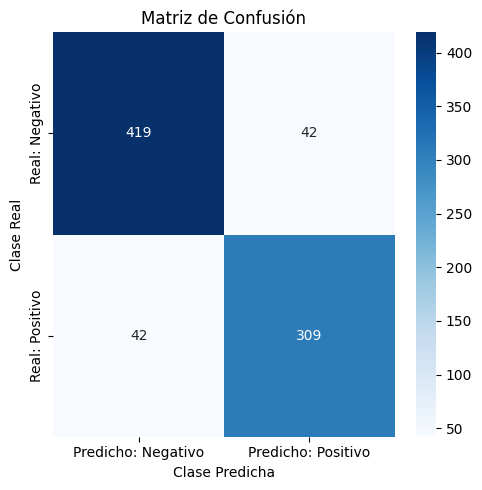

In [30]:

# Confusion Matrix
cm = confusion_matrix(y_test_walk, y_pred_walk.round())

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Predicho: Negativo', 'Predicho: Positivo'],
            yticklabels=['Real: Negativo', 'Real: Positivo'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

Miramos más en profundidad las categorías B y C (más conflictivas)

In [ ]:
test_walk_asia_BC = X_test_walk[(X_test_walk['ASIA at Rehab'] == 2.0)|(X_test_walk['ASIA at Rehab'] == 3.0)]
test_y_walk_asia_BC = df_walk.loc[test_walk_asia_BC.index]['Walk 150 ft at 1-year']

y_pred_walk_BC = clf_walk.predict_proba(test_walk_asia_BC)[:, 1]

roc_auc_BC = roc_auc_score(test_y_walk_asia_BC, y_pred_walk_BC)
accuracy_BC = accuracy_score(test_y_walk_asia_BC, y_pred_walk_BC.round())
recall_BC = recall_score(test_y_walk_asia_BC, y_pred_walk_BC.round())
f1_BC = f1_score(test_y_walk_asia_BC, y_pred_walk_BC.round())
brier_BC = brier_score_loss(test_y_walk_asia_BC, y_pred_walk_BC)

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)
print(f"ROC_AUC:           {roc_auc_BC:.3f}")
print(f"Accuracy Score:    {accuracy_BC:.3f}")
print(f"Recall:            {recall_BC:.3f}")
print(f"F1 Score:          {f1_BC:.3f}")
print(f"Brier Score Loss:  {brier_BC:.3f}")

MÉTRICAS
ROC_AUC:           0.878
Accuracy Score:    0.809
Recall:            0.761
F1 Score:          0.779
Brier Score Loss:  0.140


##### Explicabilidad con SHAP


El método permutation SHAP:

1. Se hace una predicción original con todas las variables
2. Se permuta (baraja) una variable concreta (rompe su relación con el target)
3. Se vuelve a predecir
4. Se mide cuánto cambia la predicción
5. Ese cambio se atribuye a la importancia de esa variable
6. Se repite para todas las variables y combinaciones

In [31]:
# SHAP toma 50 filas como distribución de referencia de los datos
background = shap.sample(X_train_walk, 50)

# explicador
explainer = shap.Explainer(
    clf_walk.predict_proba,
    background,
    output_names=["clase_0", "clase_1"]
)

# calcular SHAP para las 25 primeras filas de test
X_explain = X_test_walk.iloc[:25]
shap_values = explainer(X_explain)

PermutationExplainer explainer: 26it [21:00, 50.44s/it]


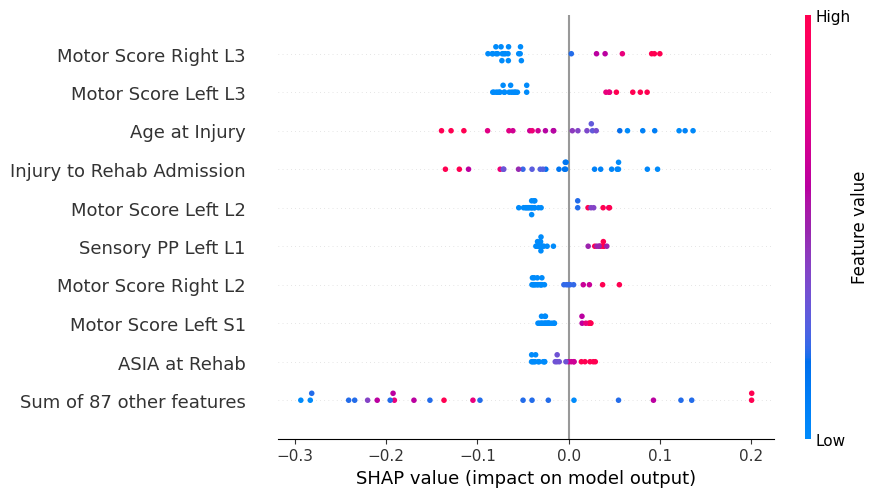

In [39]:
# explicamos la primera clase (deambula)
shap.plots.beeswarm(shap_values[:, :, 1])

# Tab PFN para categorías ASIA


In [40]:
df_asia = df.drop(columns= ["Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    'Walk 150 ft at 1-year'])

df_asia.dropna(axis=0, subset=['ASIA Score at 1-year'], inplace=True)

In [41]:
print(f'Tenemos {len(df_asia)} pacientes con ASIA válido.')

Tenemos 1449 pacientes con ASIA válido.


In [42]:
df_x_asia = df_asia.drop(columns = 'ASIA Score at 1-year')
df_y_asia = df_asia['ASIA Score at 1-year']

X_train_asia, X_test_asia, y_train_asia, y_test_asia = train_test_split(
    df_x_asia, df_y_asia, test_size=0.2, stratify=df_y_asia, random_state=52)



In [43]:
# The original code uses TabPFN 2.5 weights, which requires authentication.
# To avoid authentication issues, we will use TabPFN v2, which is publicly available.
clf_asia = TabPFNClassifier.create_default_for_version(ModelVersion.V2, ignore_pretraining_limits=True, device='cuda')

clf_asia.fit(X_train_asia, y_train_asia)

TabPFNClassifier(device='cuda', ignore_pretraining_limits=True,
                 model_path='/root/.cache/tabpfn/tabpfn-v2-classifier-finetuned-zk73skhh.ckpt')

In [44]:
y_proba_asia = clf_asia.predict_proba(X_test_asia)
y_pred_asia = clf_asia.predict(X_test_asia)

roc_auc = roc_auc_score(y_test_asia, y_proba_asia, multi_class='ovr', average='macro')
accuracy = accuracy_score(y_test_asia, y_pred_asia)
recall = recall_score(y_test_asia, y_pred_asia, average='macro')
f1 = f1_score(y_test_asia, y_pred_asia, average='macro')

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)
print(f"ROC_AUC:           {roc_auc:.3f}")
print(f"Accuracy Score:    {accuracy:.3f}")
print(f"Recall:            {recall:.3f}")
print(f"F1 Score:          {f1:.3f}")

MÉTRICAS
ROC_AUC:           0.909
Accuracy Score:    0.769
Recall:            0.494
F1 Score:          0.497


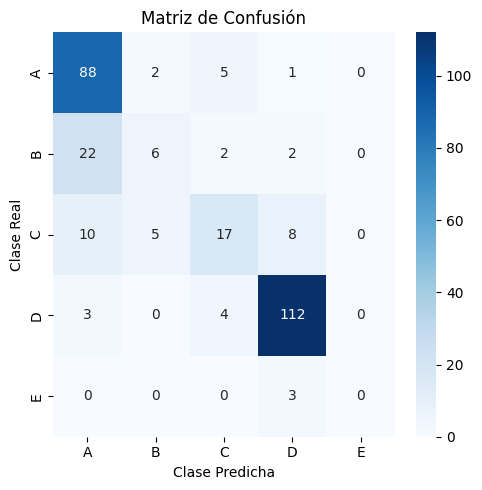

In [45]:

# Confusion Matrix
cm = confusion_matrix(y_test_asia, y_pred_asia)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

### Explicabilidad con SHAP

In [46]:
# SHAP toma 50 filas como distribución de referencia de los datos
background = shap.sample(X_train_asia, 50)

# explicador
explainer = shap.Explainer(
    clf_asia.predict_proba,
    background,
    output_names=["A", "B", "C", "D", "E",]
)

# calcular SHAP para las 25 primeras filas de test
X_explain = X_test_asia.iloc[:25]
shap_values = explainer(X_explain)

PermutationExplainer explainer: 26it [14:02, 33.69s/it]


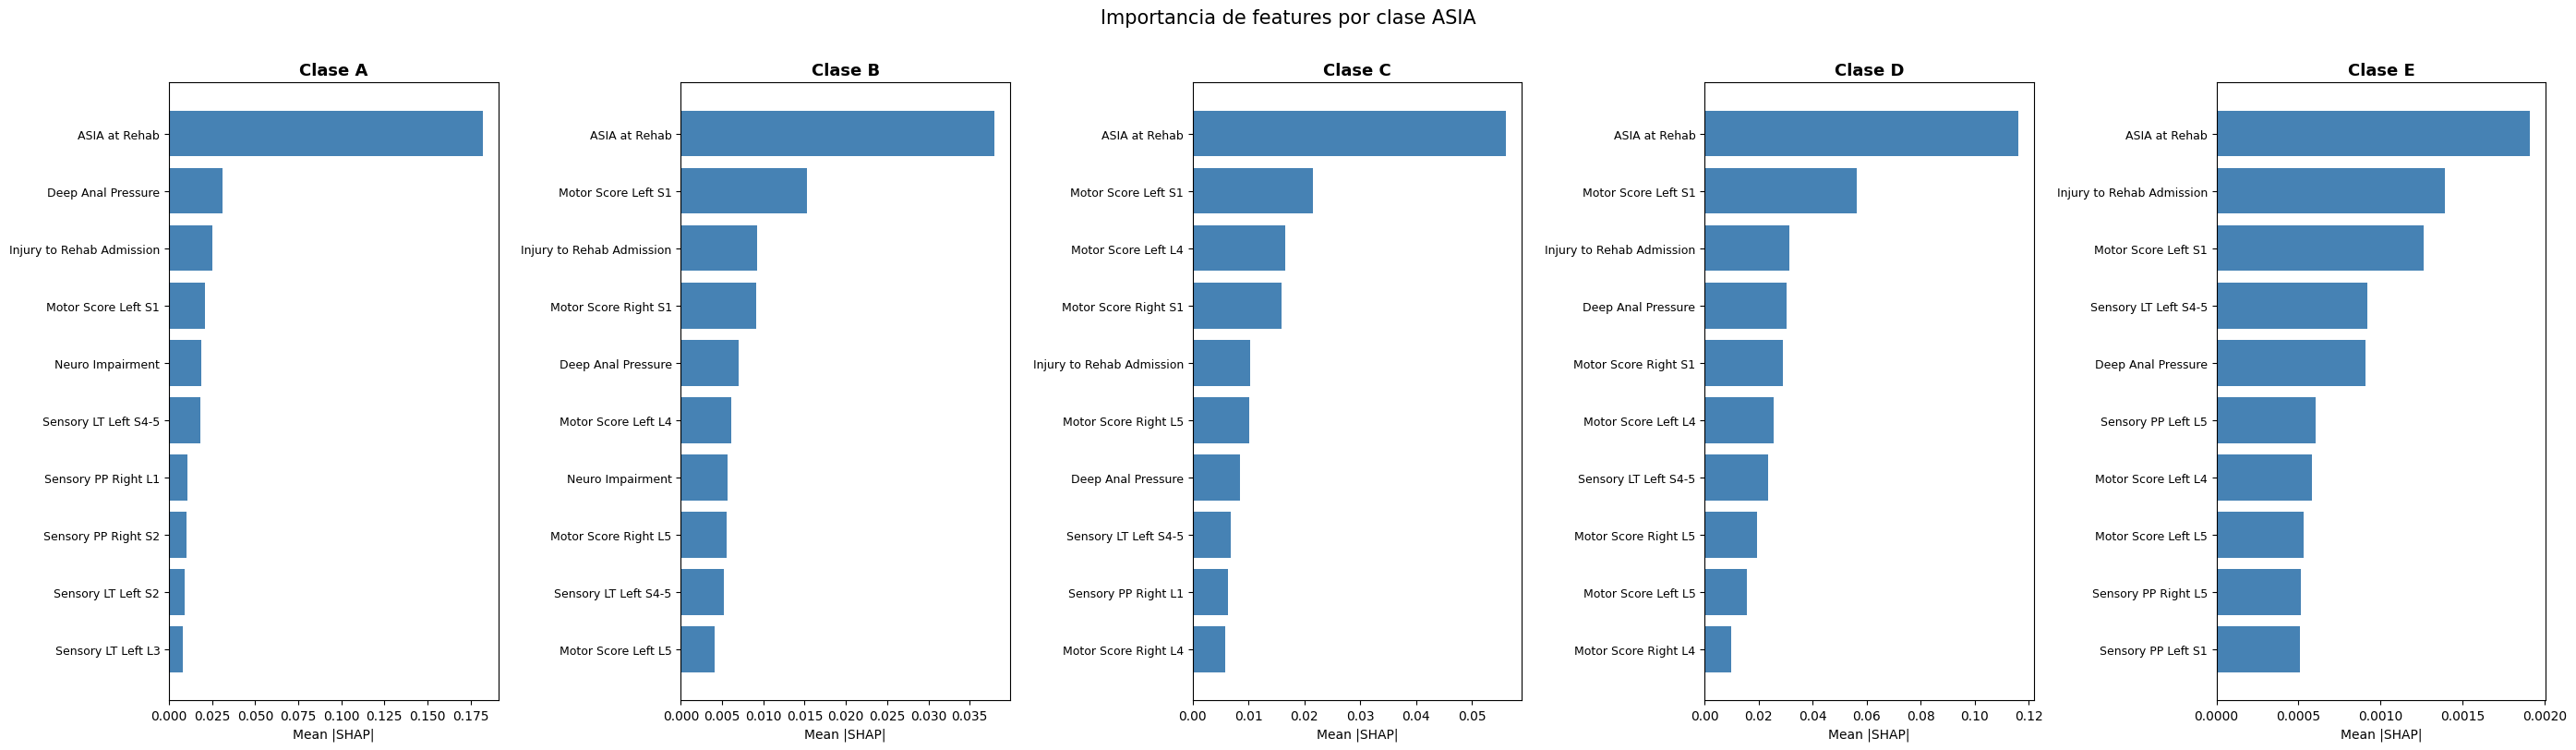

In [50]:
class_names = ["A", "B", "C", "D", "E"]
feature_names = X_explain.columns.tolist()
vals_3d = shap_values.values  # (25, 96, 5)

fig, axes = plt.subplots(1, 5, figsize=(28, 8), sharey=False)

for i, (name, ax) in enumerate(zip(class_names, axes)):
    # Importancia media absoluta para esta clase → shape (96,)
    mean_abs = np.abs(vals_3d[:, :, i]).mean(axis=0)

    # Top 10 features
    top_idx = np.argsort(mean_abs)[-10:]
    top_vals = mean_abs[top_idx]
    top_names = [feature_names[j] for j in top_idx]

    ax.barh(top_names, top_vals, color="steelblue")
    ax.set_title(f"Clase {name}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Mean |SHAP|")
    ax.tick_params(axis='y', labelsize=9)

plt.suptitle("Importancia de features por clase ASIA", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

### Examinar casos según categoría ASIA at Rehab

In [ ]:
test_asiarehab_A = X_test_asia[X_test_asia['ASIA at Rehab'] == 1].index
test_asiarehab_B = X_test_asia[X_test_asia['ASIA at Rehab'] == 2].index
test_asiarehab_C = X_test_asia[X_test_asia['ASIA at Rehab'] == 3].index
test_asiarehab_D = X_test_asia[X_test_asia['ASIA at Rehab'] == 4].index
test_asiarehab_E = X_test_asia[X_test_asia['ASIA at Rehab'] == 5].index

X_test_asiarehab_A = X_test_asia.loc[test_asiarehab_A]
X_test_asiarehab_B = X_test_asia.loc[test_asiarehab_B]
X_test_asiarehab_C = X_test_asia.loc[test_asiarehab_C]
X_test_asiarehab_D = X_test_asia.loc[test_asiarehab_D]
X_test_asiarehab_E = X_test_asia.loc[test_asiarehab_E]

y_test_asiarehab_A = y_test_asia.loc[test_asiarehab_A]
y_test_asiarehab_B = y_test_asia.loc[test_asiarehab_B]
y_test_asiarehab_C = y_test_asia.loc[test_asiarehab_C]
y_test_asiarehab_D = y_test_asia.loc[test_asiarehab_D]
y_test_asiarehab_E = y_test_asia.loc[test_asiarehab_E]

labels= [1, 2, 3, 4, 5]

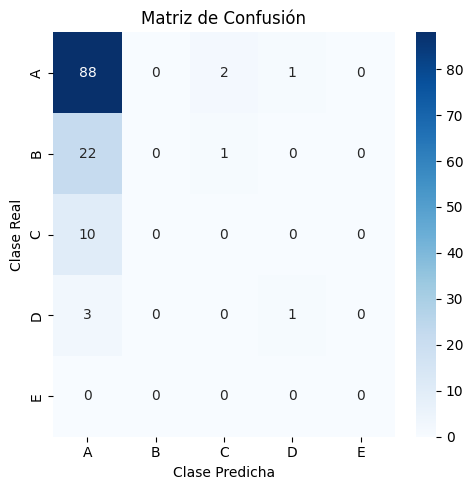

In [ ]:
# Matriz de confusión para filas con 'ASIA at Rehab' = 'A'

y_pred_asiarehab_A = clf_asia.predict(X_test_asiarehab_A)

# Confusion Matrix
cm = confusion_matrix(y_test_asiarehab_A, y_pred_asiarehab_A, labels=labels)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

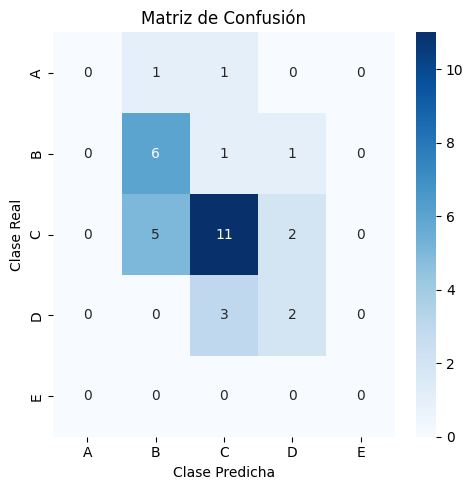

In [ ]:
# Matriz de confusión para filas con 'ASIA at Rehab' = 'B'

y_pred_asiarehab_B = clf_asia.predict(X_test_asiarehab_B)

# Confusion Matrix
cm = confusion_matrix(y_test_asiarehab_B, y_pred_asiarehab_B, labels=labels)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

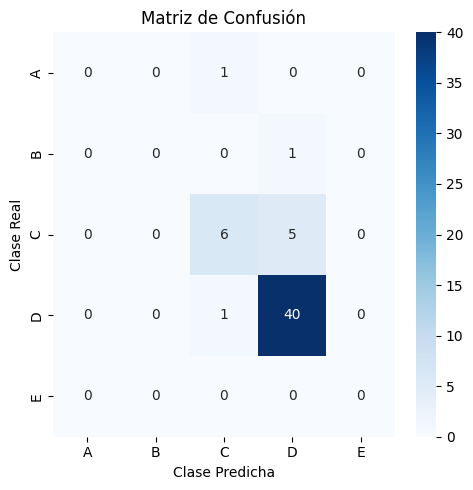

In [ ]:
# Matriz de confusión para filas con 'ASIA at Rehab' = 'C'

y_pred_asiarehab_C = clf_asia.predict(X_test_asiarehab_C)

# Confusion Matrix
cm = confusion_matrix(y_test_asiarehab_C, y_pred_asiarehab_C, labels=labels)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

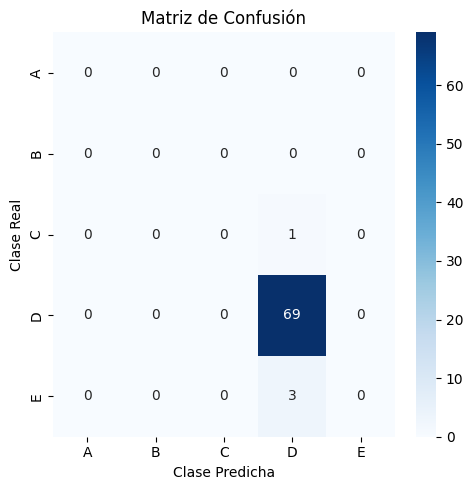

In [ ]:
# Matriz de confusión para filas con 'ASIA at Rehab' = 'D'

y_pred_asiarehab_D = clf_asia.predict(X_test_asiarehab_D)

labels = [1, 2, 3, 4, 5]

cm = confusion_matrix(y_test_asiarehab_D, y_pred_asiarehab_D, labels=labels)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

In [ ]:
# Matriz de confusión para filas con 'ASIA at Rehab' = 'E'

# NO HAY FILAS CON ASIA AT REHAB E

In [ ]:
df_asia[df_asia['ASIA Score at 1-year'] == 5]['ASIA at Rehab'].value_counts()

,count
ASIA at Rehab,
4.0,14
3.0,2


# Tab PFN para categorías ASIA (Regresor)

In [9]:
# The original code uses TabPFN 2.5 weights, which requires authentication.
# To avoid authentication issues, we will use TabPFN v2, which is publicly available.
clf_asia_reg = TabPFNRegressor.create_default_for_version(ModelVersion.V2, ignore_pretraining_limits=True, device='cuda')

clf_asia_reg.fit(X_train_asia, y_train_asia)

tabpfn-v2-regressor.ckpt:   0%|          | 0.00/44.4M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

TabPFNRegressor(device='cuda', ignore_pretraining_limits=True,
                model_path='/root/.cache/tabpfn/tabpfn-v2-regressor.ckpt')

In [10]:
pred_asia_reg = clf_asia_reg.predict(X_test_asia)

In [11]:
print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

print("Mean Squared Error (MSE): ", mean_squared_error(y_test_asia, pred_asia_reg))
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test_asia, pred_asia_reg))
print("R-squared (R^2):          ", r2_score(y_test_asia, pred_asia_reg))

MÉTRICAS
Mean Squared Error (MSE):  0.33639820559458533
Mean Absolute Error (MAE): 0.3573254281076892
R-squared (R^2):           0.8099087604532408


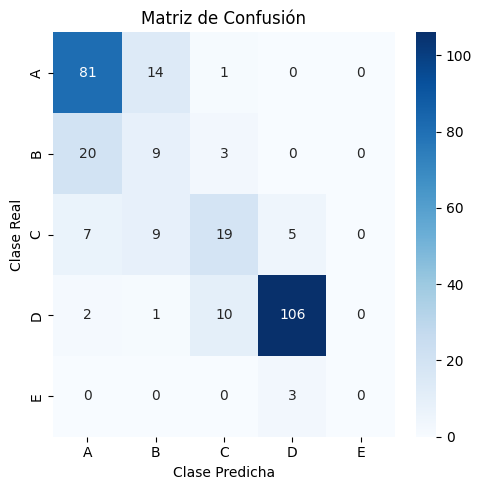

In [12]:
pred_cat_asia_reg = pred_asia_reg.round()

# Confusion Matrix
cm = confusion_matrix(y_test_asia, pred_cat_asia_reg)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

## Explicabilidad con SHAP

In [ ]:
# SHAP toma 50 filas como distribución de referencia de los datos
background = shap.sample(X_train_asia, 50)

# explicador
explainer = shap.Explainer(
    clf_asia_reg.predict,
    background,
    output_names=["A", "B", "C", "D", "E",]
)

# calcular SHAP para las 25 primeras filas de test
X_explain = X_test_asia.iloc[:25]
shap_values = explainer(X_explain)


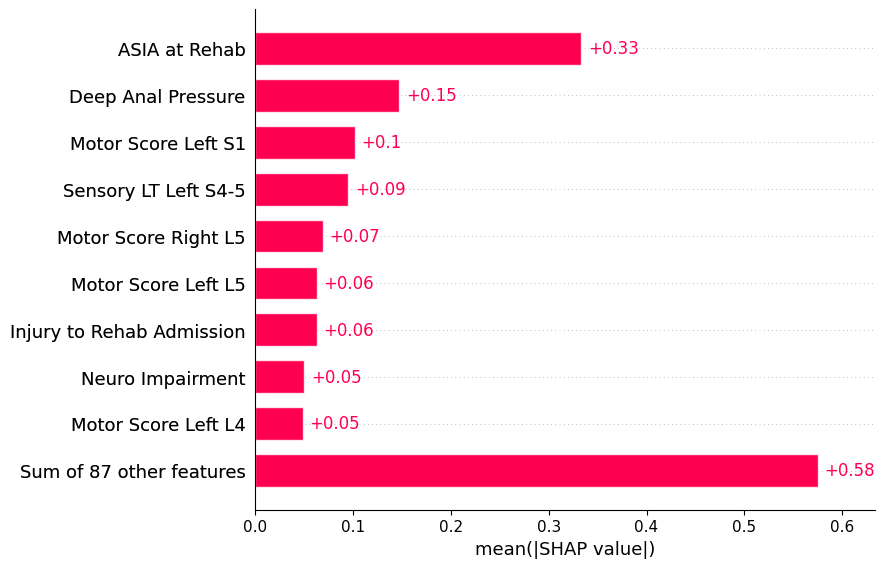

In [25]:
# gráfico de importancia media por clase
shap.plots.bar(shap_values)

# MAPIE

Usamos MAPIE (Model Agnostic Prrediction Interval Estimator) para la regresión de categorías ASIA ya que proporciona conjuntos de predicción con un intervalo de confianza, es decir, "este dato pertenece a la categoría A o B con un 95% de confianza". Así, esto no tiene mucho sentido para una clasificación binaria, pero sí para una clasificación ASIA donde hay 5 categorías.

In [51]:
from mapie.classification import SplitConformalClassifier
from mapie.regression import SplitConformalRegressor
from mapie.utils import train_conformalize_test_split

(
    X_train_mapie, X_conformalize_mapie, X_test_mapie,
    y_train_mapie, y_conformalize_mapie, y_test_mapie
) = train_conformalize_test_split(
    df_x_asia, df_y_asia, train_size=0.6, conformalize_size=0.2, test_size=0.2, random_state=52 # no existe el stratify (warining 2)
)

# confrmalize = para calcular la incertdumbre del clasificador base (tabpfn)

In [52]:
print(f'Dataset MAPIE: {len(X_train_mapie)} datos de entrenamiento, {len(X_conformalize_mapie)} datos de validación y {len(X_test_mapie)} datos de test')

Dataset MAPIE: 869 datos de entrenamiento, 290 datos de validación y 290 datos de test


## MAPIE Clasificación

In [53]:
mapie_classifier = SplitConformalClassifier(
    estimator=TabPFNClassifier.create_default_for_version(ModelVersion.V2, ignore_pretraining_limits=True, device='cuda'),
    confidence_level=0.90,
    prefit=False,
).fit(X_train_mapie, y_train_mapie).conformalize(X_conformalize_mapie, y_conformalize_mapie)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but TabPFNClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/mapie/classification.py:783: UserWarning: WARNING: your conformalization dataset has less labels than your training dataset (training has 5 unique labels while conformalization have 4 unique labels
  warnings.warn(


In [54]:
predicted_labels, predicted_sets = mapie_classifier.predict_set(X_test_mapie)

In [55]:
label_map = {
    1: "A",
    2: "B",
    3: "C",
    4: "D",
    5: "E"
}

def pred_set_to_labels(pred_set_row):
    return [label_map[i] for i, val in enumerate(pred_set_row, start=1) if val]


df_mapie_clasif = pd.DataFrame({
    "asia_real": [label_map[int(y)] for y in y_test_mapie],
    "cjto_asia_predicho": [pred_set_to_labels(row) for row in predicted_sets],
    "predicho_bool":
        [row[int(y-1)] for row, y in zip(predicted_sets, y_test_mapie)]

})

# coverage
coverage_clasif = df_mapie_clasif["predicho_bool"].apply(lambda x: x[0]).mean()

print(f'El coverage (proporción de los valores reales caen dentro del intervalo de predicción) de MAPIE de clasificación es {coverage_clasif}')

El coverage (proporción de los valores reales caen dentro del intervalo de predicción) de MAPIE de clasificación es 0.8862068965517241


In [58]:
df_mapie_clasif.head()

,asia_real,cjto_asia_predicho,predicho_bool
0,D,[D],[True]
1,D,[D],[True]
2,A,[A],[True]
3,A,"[A, B]",[True]
4,D,[D],[True]


Creamos una lista de pacientes "problemáticos", que son aquellos en los que TabPFN no puede predecir su categoría al 90% de confianza.

In [56]:
pacientes_problematicos_clasif = df_mapie_clasif[(df_mapie_clasif['predicho_bool'] == False)].index

In [57]:
len(pacientes_problematicos_clasif)

33

## MAPIE Regresión

In [59]:
mapie_regressor = SplitConformalRegressor(
    estimator=TabPFNRegressor.create_default_for_version(ModelVersion.V2, ignore_pretraining_limits=True, device='cuda'),
    confidence_level=0.90,
    prefit=False,
).fit(X_train_mapie, y_train_mapie).conformalize(X_conformalize_mapie, y_conformalize_mapie)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but TabPFNRegressor was fitted with feature names
  warnings.warn(


In [60]:
y_pred_reg, y_pred_interval_reg = mapie_regressor.predict_interval(X_test_mapie)

In [61]:
import numpy as np
import pandas as pd

label_map = {
    1: "A",
    2: "B",
    3: "C",
    4: "D",
    5: "E"
}

# función que devuelve TODAS las letras dentro del intervalo
def intervalo_map(intervalo):
    intervalo = np.array(intervalo).flatten()
    lower, upper = intervalo[0], intervalo[1]

    # usamos floor/ceil para no perder cobertura
    lower_clase = int(np.floor(lower))
    upper_clase = int(np.ceil(upper))

    # limitar al rango válido (no menor que 1 ni mayor que 5)
    lower_clase = max(1, min(5, lower_clase))
    upper_clase = max(1, min(5, upper_clase))

    return [label_map[i] for i in range(lower_clase, upper_clase + 1)]

# comprobación de cobertura
def pred_in_interval(y, intervalo):
    intervalo = np.array(intervalo).flatten()
    lower, upper = intervalo[0], intervalo[1]

    lower_clase = int(np.floor(lower))
    upper_clase = int(np.ceil(upper))

    return lower_clase <= y <= upper_clase

df_mapie_reg = pd.DataFrame({
    "asia_real": [label_map[int(y)] for y in y_test_mapie],

    # ahora devuelve lista de letras
    "cjto_asia_predicho": [
        intervalo_map(intervalo) for intervalo in y_pred_interval_reg
    ],

    "predicho_bool": [
        pred_in_interval(y, intervalo)
        for y, intervalo in zip(y_test_mapie, y_pred_interval_reg)
    ]
})

# coverage
coverage_reg = df_mapie_reg['predicho_bool'].mean()

print(f'El coverage (proporción de los valores reales caen dentro del intervalo de predicción) de MAPIE de regresión es {coverage_reg}')

El coverage (proporción de los valores reales caen dentro del intervalo de predicción) de MAPIE de regresión es 0.9827586206896551


In [62]:
df_mapie_reg.head()

,asia_real,cjto_asia_predicho,predicho_bool
0,D,"[B, C, D, E]",True
1,D,"[B, C, D, E]",True
2,A,"[A, B, C]",True
3,A,"[A, B, C]",True
4,D,"[B, C, D, E]",True


### Explicabilidad pacientes problemáticos

Al igual que en el MAPIE de clasificación, creamos otra lista de pacientes "problemáticos", que son aquellos en los que TabPFN no puede predecir su categoría al 90% de confianza.

In [63]:
pacientes_problematicos_reg = df_mapie_reg[(df_mapie_reg['predicho_bool'] == False)].index

In [64]:
len(pacientes_problematicos_reg)

5

Juntamos los pacientes problemáticos de los dos modelos y los localizamos en el conjunto de test.

In [65]:
pacientes_problematicos = set(pacientes_problematicos_clasif) | set(pacientes_problematicos_reg)

In [66]:
len(pacientes_problematicos)

33

In [67]:
index_original_problematicos = X_test_mapie.iloc[list(pacientes_problematicos)].index

Con ayuda de SHAP, explicamos concretamente las filas de pacientes problemáticos con el estimador de clasificación. Aún así, encontramos que no hay diferencias significativas entre la explicabilidad de estas columnas en específico y del resto.

In [68]:
# SHAP toma 50 filas como distribución de referencia de los datos
background = shap.sample(X_train_asia, 50)

# explicador
explainer = shap.Explainer(
    clf_asia.predict_proba,
    background,
    output_names=["clase_0", "clase_1"]
)

# calcular SHAP para las 25 primeras filas de test
X_explain = df_x_asia.loc[index_original_problematicos]
shap_values = explainer(X_explain)

PermutationExplainer explainer: 34it [17:12, 31.30s/it]


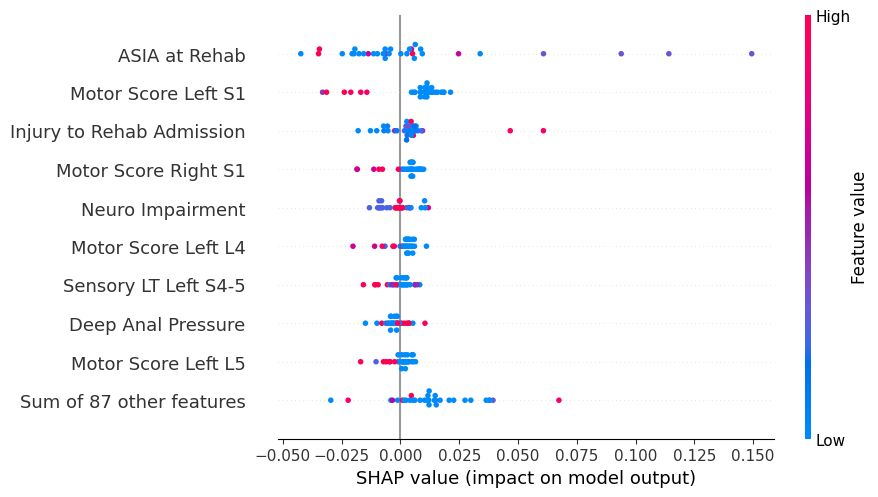

In [71]:
# explicamos la primera clase (problematicos)
shap.plots.beeswarm(shap_values[:, :, 1])

# Ampliación del dataset con nuevos datos

Como hemos podido ver en los resultados de TabPFN de clasificación, los valores de las métricas F1 y recall son bastante bajos. Así, buscamos ampliar el dataset con el que trabajamos para ver si con más datos estas métricas mejoran. Para ello, crearemos un nuevo dataset a partir de NSCISC-public-data-2021 desvinculándonos de algunos de los filtrados que teníamos anteriormente como la fecha de admisión entre 2000 y 2019, etiología traumática válida y valores válidos en todas las columnas LT y PP.

Los únicos requisitos ahora son que la fecha de primera admisión sea mayor o igual a 1994 (antes de esa fecha utilizaban un método diferente a ASIA) y que la variable de salida no sea nula.

NOTA: Debido a fallos provocados por la precisión de floats (concretamente en el cálculo del BMI), estos se han redondeado a 2 cifras decimales.

## Procesamiento anterior quitando restricciones de fecha de admisión entre 2000 y 2019, etiología traumática válida y valores válidos en todas las columnas LT y PP.

In [72]:
df_form1 = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/NSCISC-public-data-2021/f1_public_2021.csv', low_memory=False)
df_form2 = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/NSCISC-public-data-2021/f2_public_2021.csv', low_memory=False)

In [73]:
# filtramos Date of First System Admission entre mayor o igual a 1994
df_form1_filtered = df_form1[(df_form1['AAdmDt'] >= 1994)]

df_form2_1year = df_form2[df_form2['BYear'] == 1]

In [74]:
# unimos los df en uno
df_filtered_1 = df_form1_filtered.merge(df_form2_1year, how='left', on='UniID')

# nos quedamos con los que no tienen la variable de salida 'no válida' o NaN
# = 9 -> unknown
df_filtered_1 = df_filtered_1[df_filtered_1['BWlk150'] != 9.0]
df_filtered_1 = df_filtered_1.dropna(subset=['BWlk150'])

df_filtered_1 = df_filtered_1.reset_index(drop=True)

In [75]:
# Injury Etiology Category

vehicular_codes = [1, 2, 3, 4, 5, 6, 7, 8, 9]
violence_codes = [10,11,12,15]
sports_codes = [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 70, 71, 72, 73, 74, 75, 76, 77, 78]
falls_codes = [30,31]
pedestrian_code = [40]
medical_code = [50]

etiology_map = {}
for category, codes in [
    ("vehicular", vehicular_codes),
    ("violence", violence_codes),
    ("sports", sports_codes),
    ("falls", falls_codes),
    ("pedestrian", pedestrian_code),
    ("medical", medical_code)
]:
    for code in codes:
        etiology_map[code] = category

df_filtered_1['ATrmEtio'] = df_filtered_1['ATrmEtio'].map(etiology_map).fillna('Other')

# bmi, pasamos peso de libras a kg y altura de pulgadas a m

df_filtered_1['bmi'] = np.where(
    (df_filtered_1['AHghtRhb'] != 999) & (df_filtered_1['AWghtRhb'] != 999),
    (df_filtered_1['AWghtRhb'] / 2.205) / ((df_filtered_1['AHghtRhb'] * 2.54 / 100) ** 2),
    np.nan
)


# rellenamos los valores NaN de la columna 'bmi' según la mediana de las personas de su mismo sexo
# y grupo de edad (consulta con profesionales)
df_filtered_1['bmi'] = df_filtered_1['bmi'].fillna(
    df_filtered_1.groupby(['ASex', 'AInjAge'])['bmi'].transform('median')
)

df_filtered_1['bmi'] = df_filtered_1['bmi'].round(2)

In [76]:
# todas columnas del form I, menos las de at 1-year

cols_experiment = ['ASex', 'ARace', 'AHispnic', 'AMarStIj', 'AEducLvl', 'APrLvlSt', 'ATrmEtio', 'AVertInj', 'AAsscInj',
                   'ASpinSrg', 'AUMVAdm', 'ANurLvlR', 'AVoSphRb', 'AAnSnRhb', 'AASAImRb', 'ANCatRhb', 'AAnxiety', 'ADepress',
                   'ADiabete', 'AHypTen', 'AHypLip', 'AArthr', 'AAlcNbDr', 'AInjAge', 'bmi', 'AHDaSyAc', 'AI2RhADa',
                   'AASAL2RL', 'AASAL3RL', 'AASAL4RL', 'AASAL5RL', 'AASAS1RL', 'AASAL2RR', 'AASAL3RR', 'AASAL4RR', 'AASAL5RR', 'AASAS1RR',
                   'ALTL1LR', 'ALTL2LR', 'ALTL3LR', 'ALTL4LR', 'ALTL5LR', 'ALTS1LR', 'ALTS2LR', 'ALTS3LR', 'ALTS45LR',
                   'ALTL1RR', 'ALTL2RR', 'ALTL3RR', 'ALTL4RR', 'ALTL5RR', 'ALTS1RR', 'ALTS2RR', 'ALTS3RR', 'ALTS45RR',
                   'APPL1LR', 'APPL2LR', 'APPL3LR', 'APPL4LR', 'APPL5LR', 'APPS1LR', 'APPS2LR', 'APPS3LR', 'APPS45LR',
                   'APPL1RR', 'APPL2RR', 'APPL3RR', 'APPL4RR', 'APPL5RR', 'APPS1RR', 'APPS2RR', 'APPS3RR', 'APPS45RR',
                   'BWlk150', 'BWlkBlck', 'BWlkStps', 'BASAImp'

                   ]

In [77]:
variables = [
    # --- Categorical variables ---
    "Sex",
    "Race",
    "Hispanic",
    "Marital Status",
    "Education",
    "Employment Status",
    "Injury Etiology Category",
    "Vertebral Injury",
    "Associated Injury",
    "Spinal Surgery",
    "Mechanical Ventilation",
    "Neuro Level",
    "Voluntary Anal Contraction",
    "Deep Anal Pressure",
    "ASIA at Rehab",
    "Neuro Impairment",
    "Anxiety",
    "Depression",
    "Diabetes",
    "Hypertension",
    "Hyperlipidemia",
    "Arthritis",
    "Alcohol: # drinks per day",

    # --- Continuous variables ---
    "Age at Injury",
    "BMI",
    "LOS Acute Care",
    "Injury to Rehab Admission",

    # --- ASIA Sub-Tests ---
    # Motor Score
    "Motor Score Left L2",
    "Motor Score Left L3",
    "Motor Score Left L4",
    "Motor Score Left L5",
    "Motor Score Left S1",
    "Motor Score Right L2",
    "Motor Score Right L3",
    "Motor Score Right L4",
    "Motor Score Right L5",
    "Motor Score Right S1",

    # Sensory: LT
    "Sensory LT Left L1",
    "Sensory LT Left L2",
    "Sensory LT Left L3",
    "Sensory LT Left L4",
    "Sensory LT Left L5",
    "Sensory LT Left S1",
    "Sensory LT Left S2",
    "Sensory LT Left S3",
    "Sensory LT Left S4-5",
    "Sensory LT Right L1",
    "Sensory LT Right L2",
    "Sensory LT Right L3",
    "Sensory LT Right L4",
    "Sensory LT Right L5",
    "Sensory LT Right S1",
    "Sensory LT Right S2",
    "Sensory LT Right S3",
    "Sensory LT Right S4-5",

    # Sensory: Pin Prick
    "Sensory PP Left L1",
    "Sensory PP Left L2",
    "Sensory PP Left L3",
    "Sensory PP Left L4",
    "Sensory PP Left L5",
    "Sensory PP Left S1",
    "Sensory PP Left S2",
    "Sensory PP Left S3",
    "Sensory PP Left S4-5",
    "Sensory PP Right L1",
    "Sensory PP Right L2",
    "Sensory PP Right L3",
    "Sensory PP Right L4",
    "Sensory PP Right L5",
    "Sensory PP Right S1",
    "Sensory PP Right S2",
    "Sensory PP Right S3",
    "Sensory PP Right S4-5",

    # --- Endpoints ---
    "Walk 150 ft at 1-year",
    "Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    "ASIA Score at 1-year"
]


In [78]:
df_final = df_filtered_1[cols_experiment]
df_final.columns = variables

In [79]:
# 7 = declined/doesn't know 9=unknown
df_final.loc[(df_final['Sex'] == 9), 'Sex'] = np.nan
df_final.loc[(df_final['Race'] == 7)|(df_final['Race'] == 9), 'Race'] = np.nan
df_final.loc[(df_final['Hispanic'] == 7)|(df_final['Hispanic'] == 9), 'Hispanic'] = np.nan
df_final.loc[(df_final['Marital Status'] == 9), 'Marital Status'] = np.nan
df_final.loc[(df_final['Education'] == 9), 'Education'] = np.nan
df_final.loc[(df_final['Employment Status'] == 99), 'Employment Status'] = np.nan
df_final.loc[(df_final["Injury Etiology Category"] == 99), "Injury Etiology Category"] = np.nan
df_final.loc[(df_final['Vertebral Injury'] == 9), 'Vertebral Injury'] = np.nan
df_final.loc[(df_final['Associated Injury'] == 9), 'Associated Injury'] = np.nan
df_final.loc[(df_final["Spinal Surgery"] == 9), "Spinal Surgery"] = np.nan
df_final.loc[(df_final["Mechanical Ventilation"] == 9), "Mechanical Ventilation"] = np.nan
df_final.loc[(df_final["Neuro Level"] == 'X99')|(df_final["Neuro Level"] == '703')|(df_final["Neuro Level"] == "304"), "Neuro Level"] = np.nan
df_final.loc[(df_final['Voluntary Anal Contraction'] == 8)|(df_final['Voluntary Anal Contraction'] == 9), 'Voluntary Anal Contraction'] = np.nan
df_final.loc[(df_final['Deep Anal Pressure'] == 8)|(df_final['Deep Anal Pressure'] == 9), 'Deep Anal Pressure'] = np.nan

# En el experimento original, no aparece el ASIA 'E' como un factor level, es decir, no lo tienen en cuenta
df_final.loc[(df_final['ASIA at Rehab'] == 'U')|(df_final['ASIA at Rehab'] == 'E'), 'ASIA at Rehab'] = np.nan

df_final.loc[(df_final['Neuro Impairment'] == 9), 'Neuro Impairment'] = np.nan
df_final.loc[(df_final['Anxiety'] == 7)|(df_final['Anxiety'] == 9), 'Anxiety'] = np.nan
df_final.loc[(df_final['Depression'] == 7)|(df_final['Depression'] == 9), 'Depression'] = np.nan
df_final.loc[(df_final['Diabetes'] == 7)|(df_final['Diabetes'] == 9), 'Diabetes'] = np.nan
df_final.loc[(df_final['Hypertension'] == 7)|(df_final['Hypertension'] == 9), 'Hypertension'] = np.nan
df_final.loc[(df_final['Hyperlipidemia'] == 7)|(df_final['Hyperlipidemia'] == 9), 'Hyperlipidemia'] = np.nan
df_final.loc[(df_final['Arthritis'] == 7)|(df_final['Arthritis'] == 9), 'Arthritis'] = np.nan
df_final.loc[(df_final["Alcohol: # drinks per day"] == 7)|(df_final["Alcohol: # drinks per day"] == 9), "Alcohol: # drinks per day"] = np.nan

df_final.loc[(df_final['Age at Injury'] == 999), 'Age at Injury'] = np.nan

mapeo_edad = {
    '0-5y': (0+5)/2.0,
    '13-14y': (13+14)/2.0,
    '6-12y': (6+12)/2.0,
    '88+y': 90
}

# --- ASIA Sub-Tests con valor 9 -> NaN ---

asia_subtests_cols = [
    # Motor Score
    "Motor Score Left L2","Motor Score Left L3","Motor Score Left L4","Motor Score Left L5","Motor Score Left S1",
    "Motor Score Right L2","Motor Score Right L3","Motor Score Right L4","Motor Score Right L5","Motor Score Right S1",

    # Sensory: LT
    "Sensory LT Left L1","Sensory LT Left L2","Sensory LT Left L3","Sensory LT Left L4","Sensory LT Left L5",
    "Sensory LT Left S1","Sensory LT Left S2","Sensory LT Left S3","Sensory LT Left S4-5",
    "Sensory LT Right L1","Sensory LT Right L2","Sensory LT Right L3","Sensory LT Right L4","Sensory LT Right L5",
    "Sensory LT Right S1","Sensory LT Right S2","Sensory LT Right S3","Sensory LT Right S4-5",

    # Sensory: Pin Prick
    "Sensory PP Left L1","Sensory PP Left L2","Sensory PP Left L3","Sensory PP Left L4","Sensory PP Left L5",
    "Sensory PP Left S1","Sensory PP Left S2","Sensory PP Left S3","Sensory PP Left S4-5",
    "Sensory PP Right L1","Sensory PP Right L2","Sensory PP Right L3","Sensory PP Right L4","Sensory PP Right L5",
    "Sensory PP Right S1","Sensory PP Right S2","Sensory PP Right S3","Sensory PP Right S4-5"
]

# Reemplazo vectorizado
df_final[asia_subtests_cols] = df_final[asia_subtests_cols].replace(9.0, np.nan).replace(8.0, np.nan)

df_final['Age at Injury'] = df_final['Age at Injury'].replace(mapeo_edad).astype('float')

# en el paper aclaran que no hay ningún paciente con LOS Acute Care > 242
df_final.loc[df_final['LOS Acute Care'] > 242, 'LOS Acute Care'] = np.nan
df_final.loc[(df_final['Injury to Rehab Admission'] == 888), 'Injury to Rehab Admission'] = np.nan

# Motor score, sensory light touch y sensory pin prick ya nos lo hemos quitado

df_final.loc[(df_final["Walk One Block at 1-year"] == 9), "Walk One Block at 1-year"] = np.nan
df_final.loc[(df_final["Walk Flight of Stairs at 1-year"] == 9), "Walk Flight of Stairs at 1-year"] = np.nan
df_final.loc[(df_final["ASIA Score at 1-year"] == 'U'), "ASIA Score at 1-year"] = np.nan



/tmp/ipykernel_1996/2149660228.py:59: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final[asia_subtests_cols] = df_final[asia_subtests_cols].replace(9.0, np.nan).replace(8.0, np.nan)
/tmp/ipykernel_1996/2149660228.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Age at Injury'] = df_final['Age at Injury'].replace(mapeo_edad).astype('float')


#### Variables ordinales

In [80]:
# Neuro Level
map_neurolevel = {
   # Cervicales
   'C01': 1, 'C02': 2, 'C03': 3, 'C04': 4,
   'C05': 5, 'C06': 6, 'C07': 7, 'C08': 8,
   # Torácicas
   'T01': 9, 'T02': 10, 'T03': 11, 'T04': 12,
   'T05': 13, 'T06': 14, 'T07': 15, 'T08': 16,
   'T09': 17, 'T10': 18, 'T11': 19, 'T12': 20,
   # Lumbares
   'L01': 21, 'L02': 22, 'L03': 23, 'L04': 24, 'L05': 25,
   # Sacras
   'S01': 26, 'S02': 27, 'S03': 28, 'S04': 28, 'S05': 28
}


df_final['Neuro Level'] = df_final['Neuro Level'].map(map_neurolevel)


# Asia at Rehab, ASIA Score at 1-year
map_asia = {
   'A': 1,
   'B': 2,
   'C': 3,
   'D': 4,
   'E': 5
}

df_final['ASIA at Rehab'] = df_final['ASIA at Rehab'].map(map_asia)
df_final['ASIA Score at 1-year'] = df_final['ASIA Score at 1-year'].map(map_asia)


# Neuro Impairment
'''1 Paraplegia, incomplete
2 Paraplegia, complete
3 Paraplegia, minimal deficit
4 Tetraplegia, incomplete
5 Tetraplegia, complete
6 Tetraplegia, minimal deficit
7 Normal neurologic
8 Normal neurologic, minimal neurologic deficit'''


# Education

'''1 8th grade or less (includes ages 0 to 5)
2 9th through 11th grade
3 High School Diploma or G.E.D.
4 Associate Degree (A.A. – Junior College Degree)
5 Bachelor Degree
6 Master Degree
7 Doctorate (Ph.D., M.D., law degrees, etc.)
8 Other, unclassified (3-year nursing degree, special education)'''


/tmp/ipykernel_1996/3543243901.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Neuro Level'] = df_final['Neuro Level'].map(map_neurolevel)
/tmp/ipykernel_1996/3543243901.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['ASIA at Rehab'] = df_final['ASIA at Rehab'].map(map_asia)
/tmp/ipykernel_1996/3543243901.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in 

'1 8th grade or less (includes ages 0 to 5)\n2 9th through 11th grade\n3 High School Diploma or G.E.D.\n4 Associate Degree (A.A. – Junior College Degree)\n5 Bachelor Degree\n6 Master Degree\n7 Doctorate (Ph.D., M.D., law degrees, etc.)\n8 Other, unclassified (3-year nursing degree, special education)'

#### Variables categóricas

In [81]:
# Mapeo categóricas

# Sex
sex_map = {
    1: "Male",
    2: "Female",
    3: "Other, Transgender"
}

df_final['Sex'] = df_final['Sex'].map(sex_map)


# Race
race_map = {
    1: "White, Caucasian",
    2: "Black, African American",
    3: "American Indian, Alaska Native",
    4: "Asian, Pacific Islander",
    5: "Other Race, Multiracial"
}

df_final['Race'] = df_final['Race'].map(race_map)

# Hipanic -> ya está con 0 (Not Hispanic) / 1 (Hispanic)

# Marital Status

marital_status_map = {
    1: "Single, Never Married",
    2: "Married",
    3: "Divorced",
    4: "Separated",
    5: "Widowed",
    6: "Other, Unclassified",
    7: "Significant Other, Partner, Unmarried Couple"
}

df_final['Marital Status'] = df_final['Marital Status'].map(marital_status_map)


# Employment Status

employment_status_mapping = {
    1: "Working",
    2: "Homemaker",
    3: "Working", # On-the-job training
    4: "Working", # Sheltered workshop
    5: "Retired",
    6: "Student",
    7: "Unemployed",
    8: "Retired",
    9: "Retired",
    10: "Other"
}

df_final['Employment Status'] = df_final['Employment Status'].map(employment_status_mapping)


# Injury Etiology -> ya está mapeado



/tmp/ipykernel_1996/3207105089.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Sex'] = df_final['Sex'].map(sex_map)
/tmp/ipykernel_1996/3207105089.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Race'] = df_final['Race'].map(race_map)
/tmp/ipykernel_1996/3207105089.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.

Convertimos a One-Hot Encoding las columnas categóricas

In [82]:
cols_categoricas = df_final.columns[df_final.dtypes == 'object']
print(cols_categoricas)
df_final = pd.get_dummies(df_final, columns=cols_categoricas, dtype=int)


Index(['Sex', 'Race', 'Marital Status', 'Employment Status',
       'Injury Etiology Category'],
      dtype='object')


In [83]:
df_final = df_final.drop(columns= ["Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    'Walk 150 ft at 1-year'])

df_final.dropna(axis=0, subset=['ASIA Score at 1-year'], inplace=True)

In [84]:
df_ampliado_y = df_final['ASIA Score at 1-year']
df_ampliado_x = df_final.drop(columns='ASIA Score at 1-year')

Quitamos las filas que se encuentran en el conjunto de test para que no entrenemos con ellas (data leakage)

In [85]:
X_test_asia['BMI'] = X_test_asia['BMI'].round(2)

In [86]:
# 1. Resetear el índice temporalmente para no perderlo durante el merge
pacientes_test = df_ampliado_x.reset_index().merge(
    X_test_asia,
    how='inner' # 'inner' se queda solo con los que están en ambos (equivalent to 'both')
)['index'] # Extraemos la columna que contiene el índice original

# 2. Eliminamos los índices encontrados y guardamos el resultado
df_ampliado_x = df_ampliado_x.drop(index=pacientes_test)
df_ampliado_y = df_ampliado_y.drop(index=pacientes_test)

In [87]:
len(df_ampliado_x)

3604

## TabPFN con datos ampliados

In [88]:
# The original code uses TabPFN 2.5 weights, which requires authentication.
# To avoid authentication issues, we will use TabPFN v2, which is publicly available.
clf_asia_ampliado = TabPFNClassifier.create_default_for_version(ModelVersion.V2, ignore_pretraining_limits=True, device='cuda')

clf_asia_ampliado.fit(df_ampliado_x, df_ampliado_y)

TabPFNClassifier(device='cuda', ignore_pretraining_limits=True,
                 model_path='/root/.cache/tabpfn/tabpfn-v2-classifier-finetuned-zk73skhh.ckpt')

In [89]:
y_proba_asia_ampliado = clf_asia_ampliado.predict_proba(X_test_asia)
y_pred_asia_ampliado = clf_asia_ampliado.predict(X_test_asia)

roc_auc = roc_auc_score(y_test_asia, y_proba_asia_ampliado, multi_class='ovr', average='macro')
accuracy = accuracy_score(y_test_asia, y_pred_asia_ampliado)
recall = recall_score(y_test_asia, y_pred_asia_ampliado, average='macro')
f1 = f1_score(y_test_asia, y_pred_asia_ampliado, average='macro')

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)
print(f"ROC_AUC:           {roc_auc:.3f}")
print(f"Accuracy Score:    {accuracy:.3f}")
print(f"Recall:            {recall:.3f}")
print(f"F1 Score:          {f1:.3f}")

MÉTRICAS
ROC_AUC:           0.907
Accuracy Score:    0.755
Recall:            0.470
F1 Score:          0.468


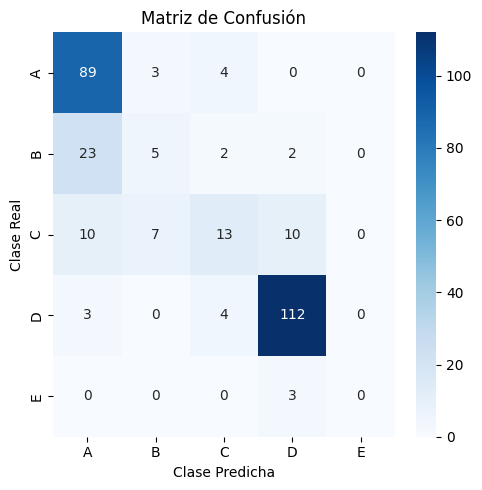

In [90]:

# Confusion Matrix
cm = confusion_matrix(y_test_asia, y_pred_asia_ampliado)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()